   FORWARD CHAINING VERIFICATION & GRAPH SYSTEM   
--- STEP 1: Enter Initial Facts ---
Fact (or 'done'): fever
Fact (or 'done'): sore_throat
Fact (or 'done'): muscle_aches
Fact (or 'done'): done

--- STEP 2: Enter Inference Rules ---
Rule (or 'done'): fever AND sore_throat -> infection
Rule (or 'done'):  infection AND muscle_aches -> test_flu
Rule (or 'done'): done

--- STEP 3: Enter Target Goal ---
Goal to verify: test_flu

                VERIFICATION RESULT               
RESULT: TRUE (Success)
🎉 The goal 'test_flu' was reached!

📊 Opening Visual Graph window... Close the window to exit script.


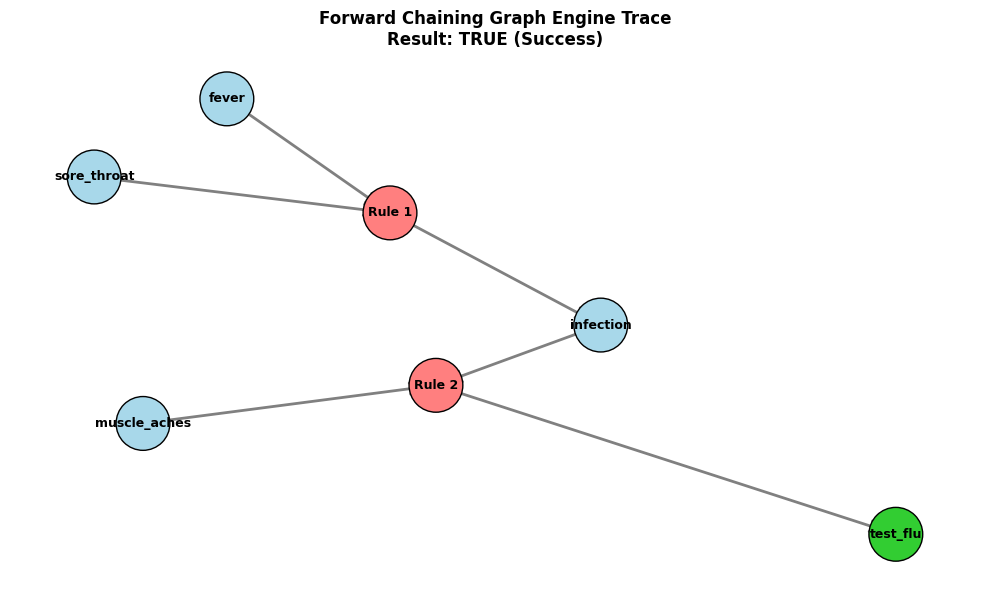

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict, deque

def run_verification_with_graph():
    print("==================================================")
    print("   FORWARD CHAINING VERIFICATION & GRAPH SYSTEM   ")
    print("==================================================")

    # 1. Collect Initial Facts
    facts = set()
    print("--- STEP 1: Enter Initial Facts ---")
    while True:
        fact_input = input("Fact (or 'done'): ").strip()
        if fact_input.lower() == 'done': break
        if fact_input: facts.add(fact_input)

    # 2. Collect Inference Rules
    rules = []
    print("\n--- STEP 2: Enter Inference Rules ---")
    while True:
        rule_input = input("Rule (or 'done'): ").strip()
        if rule_input.lower() == 'done': break
        if not rule_input or '->' not in rule_input: continue

        lhs, rhs = rule_input.split('->')
        premises = [p.strip() for p in lhs.split('AND')]
        conclusion = rhs.strip()
        rules.append({'premises': premises, 'conclusion': conclusion})

    # 3. Collect Goal
    print("\n--- STEP 3: Enter Target Goal ---")
    goal = input("Goal to verify: ").strip()

    # Setup Graph Network Tracking
    G = nx.DiGraph()
    # Add initial fact nodes
    for fact in facts:
        G.add_node(fact, type='fact', color='lightblue')

    # Forward Chaining Algorithm execution
    count = {}
    premise_to_rules = defaultdict(list)
    for i, rule in enumerate(rules):
        count[i] = len(rule['premises'])
        for premise in rule['premises']:
            premise_to_rules[premise].append(i)

    agenda = deque(list(facts))
    inferred_facts = set(facts)
    goal_proven = goal in inferred_facts

    while agenda and not goal_proven:
        current_fact = agenda.popleft()

        for rule_idx in premise_to_rules[current_fact]:
            count[rule_idx] -= 1

            if count[rule_idx] == 0:
                conclusion = rules[rule_idx]['conclusion']
                rule_node = f"Rule {rule_idx + 1}"

                # Form linkages inside our visual graph object
                G.add_node(rule_node, type='rule', color='lightcoral')
                for p in rules[rule_idx]['premises']:
                    G.add_edge(p, rule_node)
                G.add_edge(rule_node, conclusion)

                if conclusion not in inferred_facts:
                    inferred_facts.add(conclusion)
                    G.add_node(conclusion, type='fact', color='lightgreen' if conclusion == goal else 'lightblue')
                    agenda.append(conclusion)

                    if conclusion == goal:
                        goal_proven = True
                        break

    # --- SHOW TRUE / FALSE VERIFICATION RESULTS ---
    print("\n==================================================")
    print("                VERIFICATION RESULT               ")
    print("==================================================")
    if goal_proven:
        print("RESULT: TRUE (Success)")
        print(f"🎉 The goal '{goal}' was reached!")
    else:
        print("RESULT: FALSE (Failed)")
        print(f"❌ The goal '{goal}' could not be reached.")
    print("==================================================\n")

    # --- RENDER GRAPH WINDOW ---
    print("📊 Opening Visual Graph window... Close the window to exit script.")

    # Dynamically assign styling colors to nodes based on their type/state
    node_colors = []
    for node in G.nodes():
        node_attr = G.nodes[node]
        if node == goal and goal_proven:
            node_colors.append('limegreen') # Goal highlight
        elif node_attr.get('type') == 'rule':
            node_colors.append('#ff7f7f') # Rule execution nodes
        else:
            node_colors.append('#a8d8ea') # Default fact nodes

    plt.figure(figsize=(10, 6))
    plt.title(f"Forward Chaining Graph Engine Trace\nResult: {'TRUE (Success)' if goal_proven else 'FALSE (Failed)'}", fontsize=12, fontweight='bold')

    # Render layout mechanics
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx_nodes(G, pos, node_size=1500, node_color=node_colors, edgecolors='black')
    nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="gray", width=2)
    nx.draw_networkx_labels(G, pos, font_size=9, font_family="sans-serif", font_weight="bold")

    plt.axis('off')
    plt.tight_layout()
    plt.show() # Pops open the actual diagram framework box

if __name__ == "__main__":
    run_verification_with_graph()
